In [1]:
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent

import pandas as pd

# pd.set_option('display.max_columns', None)  # none은 제한값 자리(몇개 열까지 보여줄까)
# pd.set_option('display.max_rows', None)

# ============================================================
# 0. 데이터 불러오기
# ============================================================

train = pd.read_parquet(PROJECT_ROOT / 'parqueted_data' / 'train_split.parquet')

train_fe = pd.read_parquet(PROJECT_ROOT / 'parqueted_data' / '1_train_fe.parquet')

In [2]:
# ============================================================
# 1. 컬럼 분리
# ============================================================

# 시계열 컬럼군
time_cols = [
    'wl_t',          # 수위데이터 대표
    'sfc_rain_1h',   # 육상 누적강수데이터 대표
    'imerg_rain_1h', # 레이더 누적강수데이터 대표
    'radar_reflectivity_mean', # 레이더반사도 대표
    'radar_reflectivity_p95', # 레이더반사도 대표
    'target_maxrise_6h' # 종속변수: 수위상승량
]

# 수위 컬럼군
wl_cols_EDA = [
    'wl_t',
    'wl_t_minus_1h',
    'wl_t_minus_3h',
    'wl_t_minus_6h',
    'wl_t_minus_12h',
    'wl_t_minus_24h',
    'target_maxrise_6h',
]

# 수위차분(wl_diff) 컬럼군
wl_diff_cols_EDA = [
    'wl_t',
    'wl_diff_1h',
    'wl_diff_3h',
    'wl_diff_6h',
    'wl_diff_12h',
    'wl_diff_24h',
    'target_maxrise_6h',
]


# 강수 컬럼군
rain_cols = [
    # IMERG강우
    'imerg_rain_1h',
    'imerg_rain_6h',
    'imerg_rain_24h',
    # 지상강우
    'sfc_rain_1h',
    'sfc_rain_6h',
    'sfc_rain_24h',
    # 레이더 반사도
    'radar_reflectivity_mean',
    'radar_reflectivity_p95',
    'radar_reflectivity_ge20_fraction'
]

# 강우강도 컬럼군
rain_int_cols = [
    'imerg_rain_1h',
    'imerg_int_1to6h',
    'imerg_int_6to24h',
    'sfc_rain_1h',
    'sfc_int_1to6h',
    'sfc_int_6to24h'
]

# 환경 컬럼군
env_cols = [
    'cat_area',       # km²
    'wsarea',         # km²
    'mean_elevation', # m
    'mean_slope',     # °
    'urban_ratio',    # %
    'forest_ratio',   # %
    'stream_order'
]

print(len(wl_cols_EDA), len(wl_diff_cols_EDA), len(rain_cols), len(env_cols))

7 7 9 7


In [3]:
# ============================================================
# 2. 수위변수 및 종속변수간 상관계수
# ============================================================

print("피어슨 상관계수: 수위변수군")
print(
    train[wl_cols_EDA]
    .corr(
        method='pearson'
    )
    .round(2)
    .to_csv(sep='\t')
)
print()

print("스피어만 상관계수: 수위변수군")
print(
    train[wl_cols_EDA]
    .corr(
        method='spearman'
    )
    .round(2)
    .to_csv(sep='\t')
)
# 정리 필요
# 수위변수군 내부적으로 강력한 상관성이 확인됨
# 그러나 개별 변수의 종속변수에 대한 상관성은 미미함
# -> 개별값보다 시차별 수위 변화에 대한 정보가 예측에 활용됐을 가능성
# -> 차분에 의한 파생변수 생성 검토 필요


피어슨 상관계수: 수위변수군
	wl_t	wl_t_minus_1h	wl_t_minus_3h	wl_t_minus_6h	wl_t_minus_12h	wl_t_minus_24h	target_maxrise_6h
wl_t	1.0	1.0	1.0	1.0	1.0	1.0	-0.03
wl_t_minus_1h	1.0	1.0	1.0	1.0	1.0	1.0	-0.03
wl_t_minus_3h	1.0	1.0	1.0	1.0	1.0	1.0	-0.03
wl_t_minus_6h	1.0	1.0	1.0	1.0	1.0	1.0	-0.02
wl_t_minus_12h	1.0	1.0	1.0	1.0	1.0	1.0	-0.03
wl_t_minus_24h	1.0	1.0	1.0	1.0	1.0	1.0	-0.03
target_maxrise_6h	-0.03	-0.03	-0.03	-0.02	-0.03	-0.03	1.0


스피어만 상관계수: 수위변수군
	wl_t	wl_t_minus_1h	wl_t_minus_3h	wl_t_minus_6h	wl_t_minus_12h	wl_t_minus_24h	target_maxrise_6h
wl_t	1.0	1.0	0.98	0.96	0.96	0.94	-0.01
wl_t_minus_1h	1.0	1.0	0.99	0.96	0.96	0.94	-0.03
wl_t_minus_3h	0.98	0.99	1.0	0.98	0.96	0.94	-0.03
wl_t_minus_6h	0.96	0.96	0.98	1.0	0.96	0.94	-0.01
wl_t_minus_12h	0.96	0.96	0.96	0.96	1.0	0.98	-0.03
wl_t_minus_24h	0.94	0.94	0.94	0.94	0.98	1.0	-0.03
target_maxrise_6h	-0.01	-0.03	-0.03	-0.01	-0.03	-0.03	1.0



In [ ]:
# ============================================================
# 3. 수위 차분변수(wl_diff) 및 종속변수 상관계수
# ============================================================

print("피어슨 상관계수: 수위차분(wl_diff)변수군")
print(
    train_fe[wl_diff_cols_EDA]
    .corr(
        method='pearson'
    )
    .round(2)
    .to_csv(sep='\t')
)
print()

print("스피어만 상관계수: 수위차분(wl_diff)변수군")
print(
    train_fe[wl_diff_cols_EDA]
    .corr(
        method='spearman'
    )
    .round(2)
    .to_csv(sep='\t')
)

# wl_diff_6h와 종속변수(6시간 최대 수위변동)가 피어슨계수는 -0.29,
# 스피어만계수는 0.23으로 독특함
# 두 변수간의 산점도 필요

피어슨 상관계수: 수위차분(wl_diff)변수군
	wl_t	wl_diff_1h	wl_diff_3h	wl_diff_6h	wl_diff_12h	wl_diff_24h	target_maxrise_6h
wl_t	1.0	0.0	0.01	0.01	0.01	0.02	-0.03
wl_diff_1h	0.0	1.0	0.78	0.37	0.18	0.09	0.2
wl_diff_3h	0.01	0.78	1.0	0.73	0.31	0.21	-0.03
wl_diff_6h	0.01	0.37	0.73	1.0	0.49	0.4	-0.29
wl_diff_12h	0.01	0.18	0.31	0.49	1.0	0.8	0.1
wl_diff_24h	0.02	0.09	0.21	0.4	0.8	1.0	0.08
target_maxrise_6h	-0.03	0.2	-0.03	-0.29	0.1	0.08	1.0


스피어만 상관계수: 수위차분(wl_diff)변수군
	wl_t	wl_diff_1h	wl_diff_3h	wl_diff_6h	wl_diff_12h	wl_diff_24h	target_maxrise_6h
wl_t	1.0	0.02	0.05	0.08	0.09	0.1	-0.01
wl_diff_1h	0.02	1.0	0.74	0.54	0.35	0.22	0.4
wl_diff_3h	0.05	0.74	1.0	0.76	0.51	0.35	0.34
wl_diff_6h	0.08	0.54	0.76	1.0	0.68	0.49	0.23
wl_diff_12h	0.09	0.35	0.51	0.68	1.0	0.68	0.2
wl_diff_24h	0.1	0.22	0.35	0.49	0.68	1.0	0.14
target_maxrise_6h	-0.01	0.4	0.34	0.23	0.2	0.14	1.0



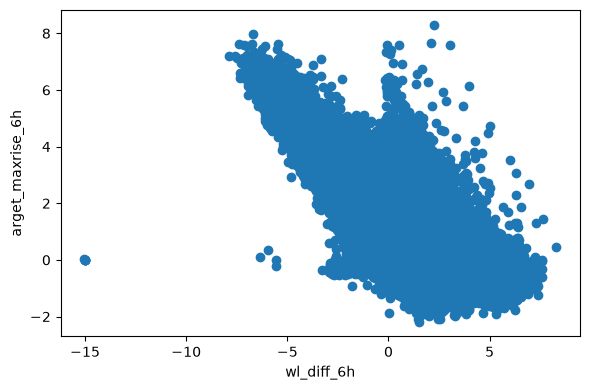

In [3]:
# 3-2. wl_diff_6h와 target_maxrise_6h간 산점도 그리기

import matplotlib.pyplot as plt

fig, ax = plt.subplots(
    1,
    1,
    figsize = (6, 4)
)

ax.scatter(train_fe['wl_diff_6h'], train_fe['target_maxrise_6h'])
ax.set_xlabel('wl_diff_6h')
ax.set_ylabel('arget_maxrise_6h')

plt.tight_layout()
plt.show()

# wl_diff_6h가 -15에 해당하는 이상치 확인

In [4]:
# 3-3. wl_diff_6h가 -15인 이상치 확인

cond_wl_out = train_fe['wl_diff_6h'] < -10
print(f"'wl_diff_6h' 파생변수 극단값 개수: {len(train_fe.loc[cond_wl_out])}")
display(train_fe.loc[cond_wl_out])  # 하나의 관측소 두개의 강우사상으로 확인

pd.set_option('display.max_columns', None)  # none은 제한값 자리(몇개 열까지 보여줄까)
pd.set_option('display.max_rows', None)

cond_wl_out_tation = train_fe['station_id'] == 'ST0445'
cond_wl_out_time1 = (train_fe['timestamp'] > '2100-08-09 00:00:00') & (train_fe['timestamp'] < '2100-08-10 00:00:00')
cond_wl_out_time2 = (train_fe['timestamp'] > '2102-09-18 00:00:00') & (train_fe['timestamp'] < '2102-09-19 00:00:00')

train_fe.loc[cond_wl_out_tation & (cond_wl_out_time1 | cond_wl_out_time2)]

'wl_diff_6h' 파생변수 극단값 개수: 6


,timestamp,station_id,wl_t,wl_t_minus_1h,wl_t_minus_3h,wl_t_minus_6h,wl_t_minus_12h,wl_t_minus_24h,imerg_rain_1h,imerg_rain_6h,...,event_id,wl_diff_1h,wl_diff_3h,wl_diff_6h,wl_diff_12h,wl_diff_24h,imerg_int_1to6h,imerg_int_6to24h,sfc_int_1to6h,sfc_int_6to24h
row_id,,,,,,,,,,,,,,,,,,,,,
TR_000386997,2100-08-09 15:00:00,ST0445,2.61,2.61,17.63,17.63,17.63,17.63,0.260,5.402,...,17,0.00,-15.02,-15.02,-15.02,-15.02,1.0284,0.750000,0.9,0.027778
TR_000589829,2102-09-18 06:00:00,ST0445,2.61,17.63,17.63,17.63,17.63,17.63,10.288,29.425,...,79,-15.02,-15.02,-15.02,-15.02,-15.02,3.8274,0.079556,0.1,0.000000
TR_000202521,2102-09-18 07:00:00,ST0445,2.61,2.61,17.63,17.63,17.63,17.63,15.390,43.244,...,79,0.00,-15.02,-15.02,-15.02,-15.02,5.5708,0.166833,0.1,0.000000
TR_000652873,2102-09-18 08:00:00,ST0445,2.61,2.61,17.63,17.63,17.63,17.63,11.410,51.874,...,79,0.00,-15.02,-15.02,-15.02,-15.02,8.0928,0.321278,0.3,0.000000
TR_000182368,2102-09-18 09:00:00,ST0445,2.59,2.61,2.61,17.63,17.63,17.63,10.039,57.052,...,79,-0.02,-0.02,-15.04,-15.04,-15.04,9.4026,0.591278,0.7,0.000000
TR_000333157,2102-09-18 10:00:00,ST0445,2.61,2.59,2.61,17.63,17.63,17.63,3.094,56.016,...,79,0.02,0.00,-15.02,-15.02,-15.02,10.5844,0.820722,1.6,0.000000


,timestamp,station_id,wl_t,wl_t_minus_1h,wl_t_minus_3h,wl_t_minus_6h,wl_t_minus_12h,wl_t_minus_24h,imerg_rain_1h,imerg_rain_6h,imerg_rain_24h,sfc_rain_1h,sfc_rain_6h,sfc_rain_24h,radar_reflectivity_mean,radar_reflectivity_p95,radar_reflectivity_ge20_fraction,cat_area,wsarea,mean_elevation,mean_slope,urban_ratio,forest_ratio,stream_order,target_maxrise_6h,event_id,wl_diff_1h,wl_diff_3h,wl_diff_6h,wl_diff_12h,wl_diff_24h,imerg_int_1to6h,imerg_int_6to24h,sfc_int_1to6h,sfc_int_6to24h
row_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
TR_000386997,2100-08-09 15:00:00,ST0445,2.61,2.61,17.63,17.63,17.63,17.63,0.260,5.402,18.902,1.5,6.0,6.5,14.035,21.163,0.1123,3.1994,583.9328,189.2,16.3235,1.1444,76.1801,2.7333,0.00,17,0.00,-15.02,-15.02,-15.02,-15.02,1.0284,0.750000,0.9,0.027778
TR_000639479,2102-09-18 01:00:00,ST0445,17.63,17.63,17.63,17.63,17.63,17.63,1.571,2.962,3.003,0.0,0.0,0.0,8.019,18.410,0.0303,3.1994,583.9328,189.2,16.3235,1.1444,76.1801,2.7333,0.00,79,0.00,0.00,0.00,0.00,0.00,0.2782,0.002278,0.0,0.000000
TR_000561875,2102-09-18 03:00:00,ST0445,17.63,17.63,17.63,17.63,17.63,17.63,4.860,10.602,10.643,0.0,0.0,0.0,16.906,21.210,0.1035,3.1994,583.9328,189.2,16.3235,1.1444,76.1801,2.7333,0.00,79,0.00,0.00,0.00,0.00,0.00,1.1484,0.002278,0.0,0.000000
TR_000258437,2102-09-18 04:00:00,ST0445,17.63,17.63,17.63,17.63,17.63,17.63,4.130,14.313,14.773,0.0,0.0,0.0,30.082,34.890,1.0000,3.1994,583.9328,189.2,16.3235,1.1444,76.1801,2.7333,0.00,79,0.00,0.00,0.00,0.00,0.00,2.0366,0.025556,0.0,0.000000
TR_000589829,2102-09-18 06:00:00,ST0445,2.61,17.63,17.63,17.63,17.63,17.63,10.288,29.425,30.857,0.0,0.5,0.5,43.002,45.702,1.0000,3.1994,583.9328,189.2,16.3235,1.1444,76.1801,2.7333,0.00,79,-15.02,-15.02,-15.02,-15.02,-15.02,3.8274,0.079556,0.1,0.000000
TR_000202521,2102-09-18 07:00:00,ST0445,2.61,2.61,17.63,17.63,17.63,17.63,15.390,43.244,46.247,1.0,1.5,1.5,45.715,48.514,1.0000,3.1994,583.9328,189.2,16.3235,1.1444,76.1801,2.7333,0.00,79,0.00,-15.02,-15.02,-15.02,-15.02,5.5708,0.166833,0.1,0.000000
TR_000652873,2102-09-18 08:00:00,ST0445,2.61,2.61,17.63,17.63,17.63,17.63,11.410,51.874,57.657,2.0,3.5,3.5,46.893,50.820,1.0000,3.1994,583.9328,189.2,16.3235,1.1444,76.1801,2.7333,0.00,79,0.00,-15.02,-15.02,-15.02,-15.02,8.0928,0.321278,0.3,0.000000
TR_000182368,2102-09-18 09:00:00,ST0445,2.59,2.61,2.61,17.63,17.63,17.63,10.039,57.052,67.695,4.5,8.0,8.0,36.758,39.556,1.0000,3.1994,583.9328,189.2,16.3235,1.1444,76.1801,2.7333,0.02,79,-0.02,-0.02,-15.04,-15.04,-15.04,9.4026,0.591278,0.7,0.000000
TR_000333157,2102-09-18 10:00:00,ST0445,2.61,2.59,2.61,17.63,17.63,17.63,3.094,56.016,70.789,7.0,15.0,15.0,36.223,38.760,1.0000,3.1994,583.9328,189.2,16.3235,1.1444,76.1801,2.7333,0.00,79,0.02,0.00,-15.02,-15.02,-15.02,10.5844,0.820722,1.6,0.000000


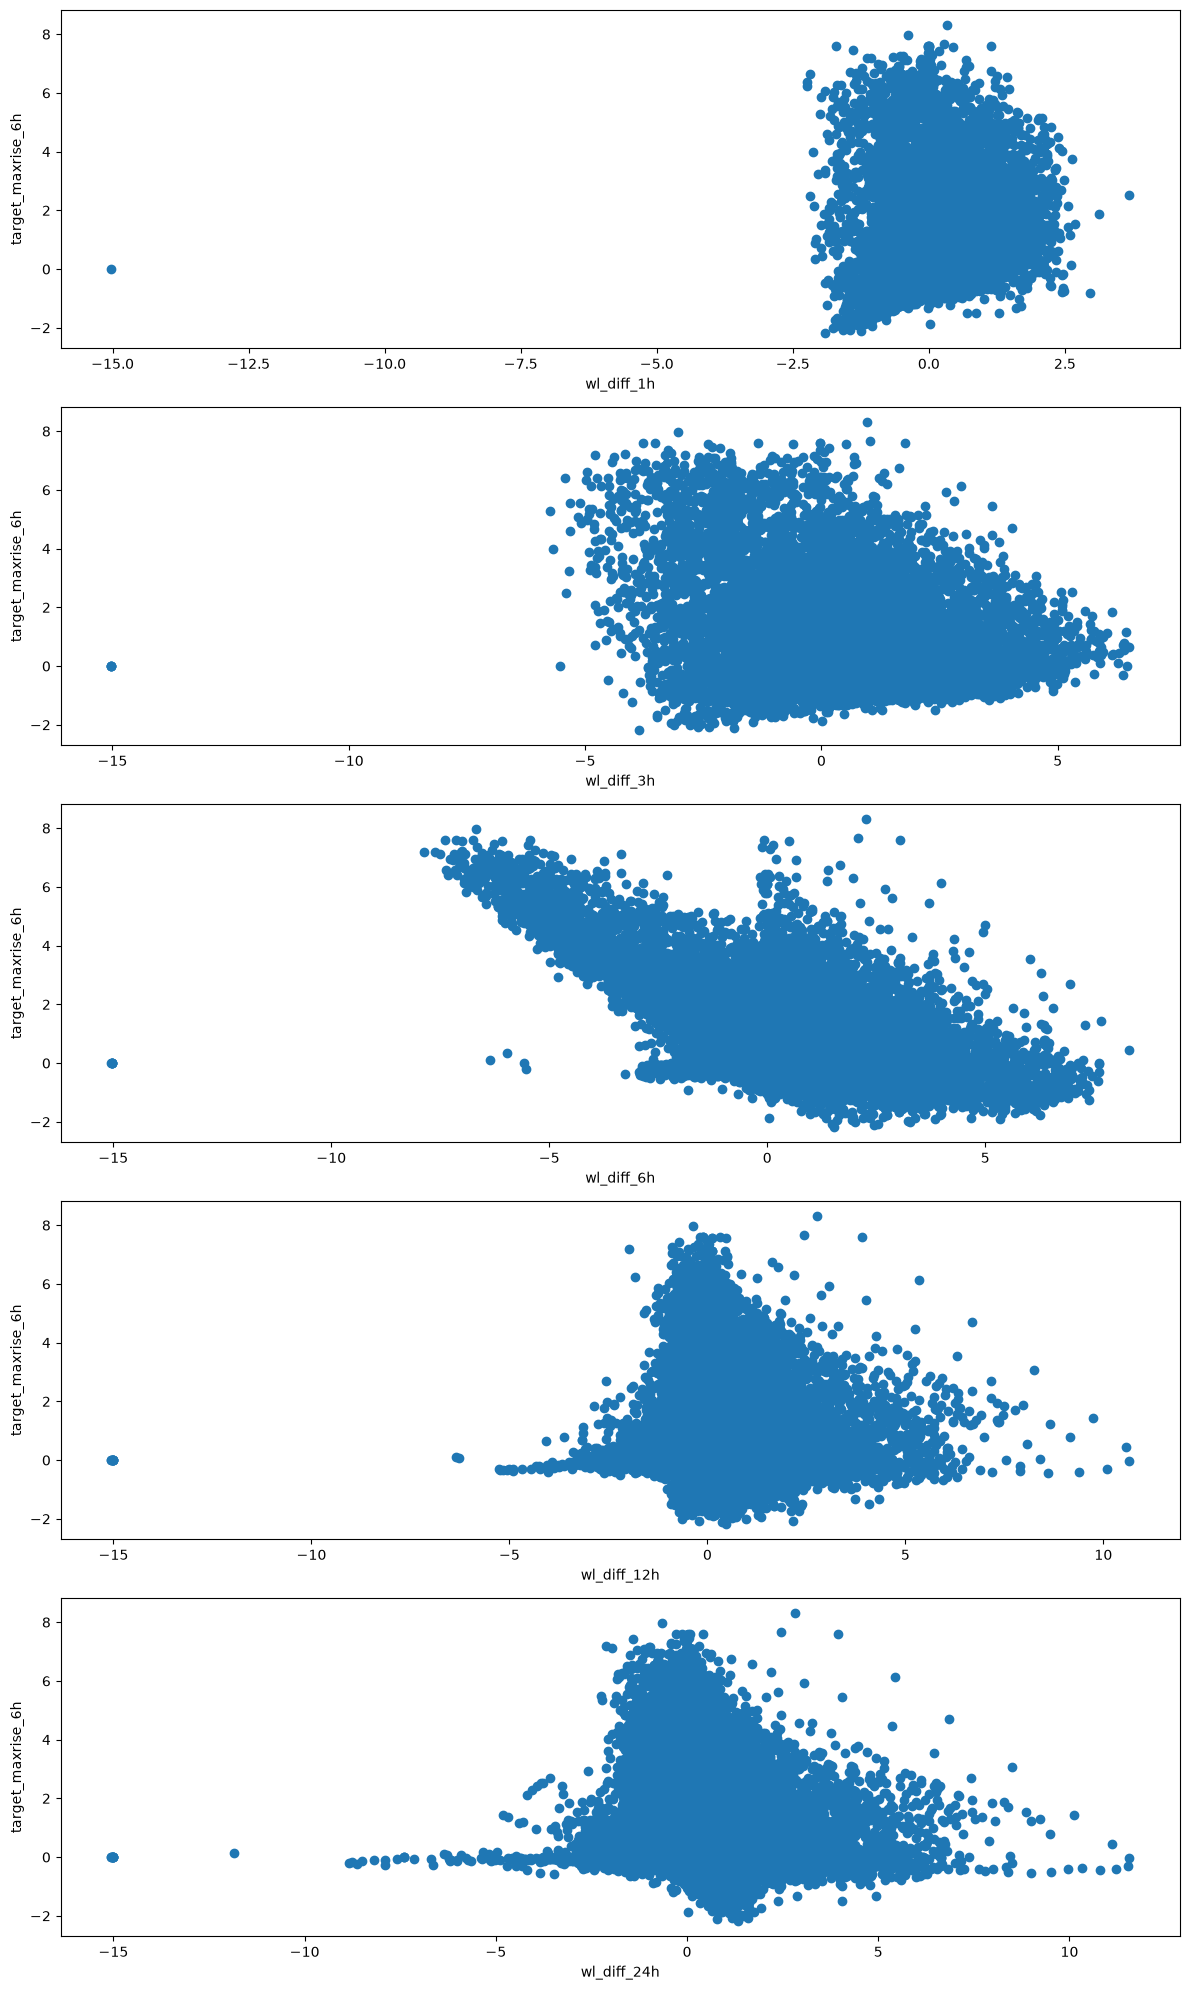

In [ ]:
# 3-4. 이상치가 확인되어 나머지 수위차분변수에도 이상치가 있는지 확인
# 1, 3, 6, 12, 24h는 모두 연계돼 있기때문
wl_diff_cols_only = [
    col for col in wl_diff_cols_EDA
    if col not in ['wl_t', 'target_maxrise_6h']
]

fig, axes = plt.subplots(
    len(wl_diff_cols_only),
    1,
    figsize=(
        12,
        4 * len(wl_diff_cols_only)
    )
)

if len(wl_diff_cols_only) == 1: # cols에 한개 열만 오면 axes = [ax1, ax2...]만 반환
    axes = [axes]  # axes = [[ax1, ax2]]가 돼야 행열(0행 0, 1열) 접근이 가능

for i, col in enumerate(wl_diff_cols_only):
    x = train_fe[col].dropna()  # 플롯을 여러개 그릴 예정, 플롯할 데이터를 하나의 변수로 묶어놓기(col임을 주의)

    axes[i].scatter(x, train_fe['target_maxrise_6h']) 
    axes[i].tick_params(labelsize = 10)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('target_maxrise_6h')

plt.tight_layout()  # 자동 간격조정(배치관리)
plt.show()


In [19]:
cond_wl_out_all = (
    train_fe[wl_diff_cols_only] < -10
).any(axis=1)
print(f"수위차분변수 극단값 개수: {len(train_fe.loc[cond_wl_out_all])}")
display(train_fe.loc[cond_wl_out_all])  # 하나의 관측소 두개의 강우사상으로 확인
print()

#cond_wl_out_tation = train_fe['station_id'] == ['ST0445'] 앞에 정의됨
cond_wl_out_time1 = (train_fe['timestamp'] > '2100-08-09 00:00:00') & (train_fe['timestamp'] < '2100-08-10 00:00:00')
cond_wl_out_time2 = (train_fe['timestamp'] > '2102-09-17 00:00:00') & (train_fe['timestamp'] < '2102-09-19 00:00:00')
cond_wl_out_time3 = (train_fe['timestamp'] > '2101-11-02 00:00:00') & (train_fe['timestamp'] < '2101-11-03 00:00:00')

print("ST0445 이상치 의심 강우사상 3개")
display(train_fe.loc[
    cond_wl_out_tation & (
        cond_wl_out_time1 | cond_wl_out_time2 | cond_wl_out_time3
    )
])

print()

print("ST0066 이상치 의심 강우사상 3개")
cond_wl_out_station2 = train_fe['station_id'] == 'ST0066'
cond_wl_out_time4 = (train_fe['timestamp'] > '2102-03-31 00:00:00') & (train_fe['timestamp'] < '2102-04-02 00:00:00')
display(train_fe.loc[
    cond_wl_out_station2 & cond_wl_out_time4
])

수위차분변수 극단값 개수: 10


,timestamp,station_id,wl_t,wl_t_minus_1h,wl_t_minus_3h,wl_t_minus_6h,wl_t_minus_12h,wl_t_minus_24h,imerg_rain_1h,imerg_rain_6h,imerg_rain_24h,sfc_rain_1h,sfc_rain_6h,sfc_rain_24h,radar_reflectivity_mean,radar_reflectivity_p95,radar_reflectivity_ge20_fraction,cat_area,wsarea,mean_elevation,mean_slope,urban_ratio,forest_ratio,stream_order,target_maxrise_6h,event_id,wl_diff_1h,wl_diff_3h,wl_diff_6h,wl_diff_12h,wl_diff_24h,imerg_int_1to6h,imerg_int_6to24h,sfc_int_1to6h,sfc_int_6to24h
row_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
TR_000386997,2100-08-09 15:00:00,ST0445,2.61,2.61,17.63,17.63,17.63,17.63,0.260,5.402,18.902,1.5,6.0,6.5,14.035,21.163,0.1123,3.1994,583.9328,189.20,16.3235,1.1444,76.1801,2.7333,0.00,17,0.00,-15.02,-15.02,-15.02,-15.02,1.0284,0.750000,0.9,0.027778
TR_000202940,2101-11-02 07:00:00,ST0445,2.58,2.58,2.58,2.59,17.63,17.63,1.200,2.311,3.282,0.0,0.0,0.0,14.276,19.350,0.0244,3.1994,583.9328,189.20,16.3235,1.1444,76.1801,2.7333,0.01,54,0.00,0.00,-0.01,-15.05,-15.05,0.2222,0.053944,0.0,0.000000
TR_000205403,2101-11-02 09:00:00,ST0445,2.58,2.58,2.58,2.59,17.63,17.63,1.974,6.854,8.433,0.5,0.5,0.5,20.299,27.500,0.4531,3.1994,583.9328,189.20,16.3235,1.1444,76.1801,2.7333,0.01,54,0.00,0.00,-0.01,-15.05,-15.05,0.9760,0.087722,0.0,0.000000
TR_000437549,2102-04-01 00:00:00,ST0066,11.60,11.60,11.55,11.47,11.34,23.45,0.000,0.000,0.168,0.0,1.5,16.0,3.554,17.786,0.0234,2.8934,26.0732,537.46,20.5159,1.7481,94.0463,1.7273,0.15,67,0.00,0.05,0.13,0.26,-11.85,0.0000,0.009333,0.3,0.805556
TR_000589829,2102-09-18 06:00:00,ST0445,2.61,17.63,17.63,17.63,17.63,17.63,10.288,29.425,30.857,0.0,0.5,0.5,43.002,45.702,1.0000,3.1994,583.9328,189.20,16.3235,1.1444,76.1801,2.7333,0.00,79,-15.02,-15.02,-15.02,-15.02,-15.02,3.8274,0.079556,0.1,0.000000
TR_000202521,2102-09-18 07:00:00,ST0445,2.61,2.61,17.63,17.63,17.63,17.63,15.390,43.244,46.247,1.0,1.5,1.5,45.715,48.514,1.0000,3.1994,583.9328,189.20,16.3235,1.1444,76.1801,2.7333,0.00,79,0.00,-15.02,-15.02,-15.02,-15.02,5.5708,0.166833,0.1,0.000000
TR_000652873,2102-09-18 08:00:00,ST0445,2.61,2.61,17.63,17.63,17.63,17.63,11.410,51.874,57.657,2.0,3.5,3.5,46.893,50.820,1.0000,3.1994,583.9328,189.20,16.3235,1.1444,76.1801,2.7333,0.00,79,0.00,-15.02,-15.02,-15.02,-15.02,8.0928,0.321278,0.3,0.000000
TR_000182368,2102-09-18 09:00:00,ST0445,2.59,2.61,2.61,17.63,17.63,17.63,10.039,57.052,67.695,4.5,8.0,8.0,36.758,39.556,1.0000,3.1994,583.9328,189.20,16.3235,1.1444,76.1801,2.7333,0.02,79,-0.02,-0.02,-15.04,-15.04,-15.04,9.4026,0.591278,0.7,0.000000
TR_000333157,2102-09-18 10:00:00,ST0445,2.61,2.59,2.61,17.63,17.63,17.63,3.094,56.016,70.789,7.0,15.0,15.0,36.223,38.760,1.0000,3.1994,583.9328,189.20,16.3235,1.1444,76.1801,2.7333,0.00,79,0.02,0.00,-15.02,-15.02,-15.02,10.5844,0.820722,1.6,0.000000



ST0445 이상치 의심 강우사상 3개


,timestamp,station_id,wl_t,wl_t_minus_1h,wl_t_minus_3h,wl_t_minus_6h,wl_t_minus_12h,wl_t_minus_24h,imerg_rain_1h,imerg_rain_6h,imerg_rain_24h,sfc_rain_1h,sfc_rain_6h,sfc_rain_24h,radar_reflectivity_mean,radar_reflectivity_p95,radar_reflectivity_ge20_fraction,cat_area,wsarea,mean_elevation,mean_slope,urban_ratio,forest_ratio,stream_order,target_maxrise_6h,event_id,wl_diff_1h,wl_diff_3h,wl_diff_6h,wl_diff_12h,wl_diff_24h,imerg_int_1to6h,imerg_int_6to24h,sfc_int_1to6h,sfc_int_6to24h
row_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
TR_000386997,2100-08-09 15:00:00,ST0445,2.61,2.61,17.63,17.63,17.63,17.63,0.260,5.402,18.902,1.5,6.0,6.5,14.035,21.163,0.1123,3.1994,583.9328,189.2,16.3235,1.1444,76.1801,2.7333,0.00,17,0.00,-15.02,-15.02,-15.02,-15.02,1.0284,0.750000,0.9,0.027778
TR_000202940,2101-11-02 07:00:00,ST0445,2.58,2.58,2.58,2.59,17.63,17.63,1.200,2.311,3.282,0.0,0.0,0.0,14.276,19.350,0.0244,3.1994,583.9328,189.2,16.3235,1.1444,76.1801,2.7333,0.01,54,0.00,0.00,-0.01,-15.05,-15.05,0.2222,0.053944,0.0,0.000000
TR_000205403,2101-11-02 09:00:00,ST0445,2.58,2.58,2.58,2.59,17.63,17.63,1.974,6.854,8.433,0.5,0.5,0.5,20.299,27.500,0.4531,3.1994,583.9328,189.2,16.3235,1.1444,76.1801,2.7333,0.01,54,0.00,0.00,-0.01,-15.05,-15.05,0.9760,0.087722,0.0,0.000000
TR_000639479,2102-09-18 01:00:00,ST0445,17.63,17.63,17.63,17.63,17.63,17.63,1.571,2.962,3.003,0.0,0.0,0.0,8.019,18.410,0.0303,3.1994,583.9328,189.2,16.3235,1.1444,76.1801,2.7333,0.00,79,0.00,0.00,0.00,0.00,0.00,0.2782,0.002278,0.0,0.000000
TR_000561875,2102-09-18 03:00:00,ST0445,17.63,17.63,17.63,17.63,17.63,17.63,4.860,10.602,10.643,0.0,0.0,0.0,16.906,21.210,0.1035,3.1994,583.9328,189.2,16.3235,1.1444,76.1801,2.7333,0.00,79,0.00,0.00,0.00,0.00,0.00,1.1484,0.002278,0.0,0.000000
TR_000258437,2102-09-18 04:00:00,ST0445,17.63,17.63,17.63,17.63,17.63,17.63,4.130,14.313,14.773,0.0,0.0,0.0,30.082,34.890,1.0000,3.1994,583.9328,189.2,16.3235,1.1444,76.1801,2.7333,0.00,79,0.00,0.00,0.00,0.00,0.00,2.0366,0.025556,0.0,0.000000
TR_000589829,2102-09-18 06:00:00,ST0445,2.61,17.63,17.63,17.63,17.63,17.63,10.288,29.425,30.857,0.0,0.5,0.5,43.002,45.702,1.0000,3.1994,583.9328,189.2,16.3235,1.1444,76.1801,2.7333,0.00,79,-15.02,-15.02,-15.02,-15.02,-15.02,3.8274,0.079556,0.1,0.000000
TR_000202521,2102-09-18 07:00:00,ST0445,2.61,2.61,17.63,17.63,17.63,17.63,15.390,43.244,46.247,1.0,1.5,1.5,45.715,48.514,1.0000,3.1994,583.9328,189.2,16.3235,1.1444,76.1801,2.7333,0.00,79,0.00,-15.02,-15.02,-15.02,-15.02,5.5708,0.166833,0.1,0.000000
TR_000652873,2102-09-18 08:00:00,ST0445,2.61,2.61,17.63,17.63,17.63,17.63,11.410,51.874,57.657,2.0,3.5,3.5,46.893,50.820,1.0000,3.1994,583.9328,189.2,16.3235,1.1444,76.1801,2.7333,0.00,79,0.00,-15.02,-15.02,-15.02,-15.02,8.0928,0.321278,0.3,0.000000



ST0066 이상치 의심 강우사상 3개


,timestamp,station_id,wl_t,wl_t_minus_1h,wl_t_minus_3h,wl_t_minus_6h,wl_t_minus_12h,wl_t_minus_24h,imerg_rain_1h,imerg_rain_6h,imerg_rain_24h,sfc_rain_1h,sfc_rain_6h,sfc_rain_24h,radar_reflectivity_mean,radar_reflectivity_p95,radar_reflectivity_ge20_fraction,cat_area,wsarea,mean_elevation,mean_slope,urban_ratio,forest_ratio,stream_order,target_maxrise_6h,event_id,wl_diff_1h,wl_diff_3h,wl_diff_6h,wl_diff_12h,wl_diff_24h,imerg_int_1to6h,imerg_int_6to24h,sfc_int_1to6h,sfc_int_6to24h
row_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
TR_000437549,2102-04-01 00:00:00,ST0066,11.60,11.60,11.55,11.47,11.34,23.45,0.000,0.000,0.168,0.0,1.5,16.0,3.554,17.786,0.0234,2.8934,26.0732,537.46,20.5159,1.7481,94.0463,1.7273,0.15,67,0.00,0.05,0.13,0.26,-11.85,0.0000,0.009333,0.3,0.805556
TR_000252105,2102-04-01 01:00:00,ST0066,11.63,11.60,11.57,11.48,11.36,11.08,0.000,0.000,0.168,0.5,2.0,15.5,5.183,21.930,0.1172,2.8934,26.0732,537.46,20.5159,1.7481,94.0463,1.7273,0.17,67,0.03,0.06,0.15,0.27,0.55,0.0000,0.009333,0.3,0.750000
TR_000598157,2102-04-01 02:00:00,ST0066,11.65,11.63,11.60,11.53,11.39,11.11,0.000,0.000,0.114,0.0,1.0,15.5,18.224,29.820,0.3105,2.8934,26.0732,537.46,20.5159,1.7481,94.0463,1.7273,0.15,67,0.02,0.05,0.12,0.26,0.54,0.0000,0.006333,0.2,0.805556
TR_000496451,2102-04-01 03:00:00,ST0066,11.66,11.65,11.60,11.55,11.41,11.14,0.000,0.000,0.114,0.0,0.5,12.5,20.444,25.510,0.5850,2.8934,26.0732,537.46,20.5159,1.7481,94.0463,1.7273,0.19,67,0.01,0.06,0.11,0.25,0.52,0.0000,0.006333,0.1,0.666667
TR_000339986,2102-04-01 04:00:00,ST0066,11.69,11.66,11.63,11.57,11.43,11.16,0.000,0.000,0.020,0.0,0.5,12.5,17.731,24.060,0.2363,2.8934,26.0732,537.46,20.5159,1.7481,94.0463,1.7273,0.18,67,0.03,0.06,0.12,0.26,0.53,0.0000,0.001111,0.1,0.666667
TR_000511133,2102-04-01 05:00:00,ST0066,11.71,11.69,11.65,11.60,11.45,11.18,8.006,8.006,8.026,0.5,1.0,12.5,26.963,32.675,0.9023,2.8934,26.0732,537.46,20.5159,1.7481,94.0463,1.7273,0.20,67,0.02,0.06,0.11,0.26,0.53,0.0000,0.001111,0.1,0.638889
TR_000149256,2102-04-01 06:00:00,ST0066,11.75,11.71,11.66,11.60,11.47,11.20,3.969,11.976,11.976,14.5,15.5,17.5,40.140,50.680,1.0000,2.8934,26.0732,537.46,20.5159,1.7481,94.0463,1.7273,0.21,67,0.04,0.09,0.15,0.28,0.55,1.6014,0.000000,0.2,0.111111
TR_000250066,2102-04-01 07:00:00,ST0066,11.80,11.75,11.69,11.63,11.48,11.22,0.570,12.546,12.546,12.5,27.5,29.5,14.255,25.396,0.3164,2.8934,26.0732,537.46,20.5159,1.7481,94.0463,1.7273,0.19,67,0.05,0.11,0.17,0.32,0.58,2.3952,0.000000,3.0,0.111111
TR_000245805,2102-04-01 08:00:00,ST0066,11.80,11.80,11.71,11.65,11.53,11.24,0.000,12.546,12.546,0.0,27.5,29.5,2.559,24.620,0.0771,2.8934,26.0732,537.46,20.5159,1.7481,94.0463,1.7273,0.23,67,0.00,0.09,0.15,0.27,0.56,2.5092,0.000000,5.5,0.111111


In [22]:
# 3-4. wl_diff_6h가 -15인 이상치가 val, test 셋에도 있는지 확인 필요: 없음

val_fe = pd.read_parquet(PROJECT_ROOT / 'parqueted_data' / '1_val_fe.parquet')
test_fe = pd.read_parquet(PROJECT_ROOT / 'parqueted_data' / '1_test_fe.parquet')

for name, df in [('train_fe', train_fe), ('val_fe', val_fe), ('test_fe', test_fe)]:

    df.loc[df['wl_diff_1h'] < -10]
    df.loc[df['wl_diff_3h'] < -10]
    df.loc[df['wl_diff_6h'] < -10]
    df.loc[df['wl_diff_12h'] < -10]
    df.loc[df['wl_diff_24h'] < -10]

    print(
         f"{name}의 1/3/6/12/24h 차분값 이상치 개수: "
         f"{len(df.loc[df['wl_diff_6h'] < -10])} /"
         f"{len(df.loc[df['wl_diff_3h'] < -10])} /"
         f"{len(df.loc[df['wl_diff_6h'] < -10])} /"
         f"{len(df.loc[df['wl_diff_12h'] < -10])} /"
         f"{len(df.loc[df['wl_diff_24h'] < -10])} /"
    )

train_fe의 1/3/6/12/24h 차분값 이상치 개수: 6 /4 /6 /9 /10 /
val_fe의 1/3/6/12/24h 차분값 이상치 개수: 0 /0 /0 /0 /0 /
test_fe의 1/3/6/12/24h 차분값 이상치 개수: 0 /0 /0 /0 /0 /


In [26]:
# ============================================================
# 3-5. 확인된 이상치(train에만 있음) 제거
# ============================================================

# 이상치 row_id 추출
wl_error_row_id = [
    'TR_000386997',
    'TR_000202940',
    'TR_000205403',
    'TR_000639479',
    'TR_000561875',
    'TR_000258437',
    'TR_000589829',
    'TR_000202521',
    'TR_000652873',
    'TR_000182368',
    'TR_000333157',
    'TR_000682989',
    'TR_000437549'
]

print(f"이상치 제거 전 데이터 크기: {train_fe.shape}")

train_fe_v2 = train_fe.drop(
    index = wl_error_row_id
)

print(f"이상치 제거 후 데이터 크기: {train_fe_v2.shape}")

train_fe_v2.to_parquet(PROJECT_ROOT / 'parqueted_data' / '3_train_clean.parquet')

이상치 제거 전 데이터 크기: (616331, 35)
이상치 제거 후 데이터 크기: (616318, 35)


In [ ]:
# ============================================================
# 4. 강우변수 및 종속변수 상관계수
# ============================================================

print("피어슨_상관계수: 강우변수군")
print(
    train[rain_cols + ['target_maxrise_6h']]
    .corr(method='pearson')
    .round(2)
    .to_csv(sep='\t')
)
print()

print("스피어만_상관계수: 강우변수군")
print(
    train[rain_cols + ['target_maxrise_6h']]
    .corr(method='spearman')
    .round(2)
    .to_csv(sep='\t')
)

print()

피어슨_상관계수: 강우변수군
	imerg_rain_1h	imerg_rain_6h	imerg_rain_24h	sfc_rain_1h	sfc_rain_6h	sfc_rain_24h	radar_reflectivity_mean	radar_reflectivity_p95	radar_reflectivity_ge20_fraction	target_maxrise_6h
imerg_rain_1h	1.0	0.65	0.4	0.36	0.29	0.2	0.49	0.42	0.47	0.19
imerg_rain_6h	0.65	1.0	0.69	0.42	0.58	0.42	0.5	0.43	0.49	0.2
imerg_rain_24h	0.4	0.69	1.0	0.29	0.5	0.72	0.34	0.31	0.33	0.16
sfc_rain_1h	0.36	0.42	0.29	1.0	0.62	0.39	0.45	0.41	0.43	0.26
sfc_rain_6h	0.29	0.58	0.5	0.62	1.0	0.7	0.38	0.35	0.36	0.25
sfc_rain_24h	0.2	0.42	0.72	0.39	0.7	1.0	0.25	0.26	0.24	0.19
radar_reflectivity_mean	0.49	0.5	0.34	0.45	0.38	0.25	1.0	0.91	0.92	0.19
radar_reflectivity_p95	0.42	0.43	0.31	0.41	0.35	0.26	0.91	1.0	0.82	0.18
radar_reflectivity_ge20_fraction	0.47	0.49	0.33	0.43	0.36	0.24	0.92	0.82	1.0	0.18
target_maxrise_6h	0.19	0.2	0.16	0.26	0.25	0.19	0.19	0.18	0.18	1.0


스피어만_상관계수: 강우변수군
	imerg_rain_1h	imerg_rain_6h	imerg_rain_24h	sfc_rain_1h	sfc_rain_6h	sfc_rain_24h	radar_reflectivity_mean	radar_reflectivity_p95	ra

In [ ]:
# ============================================================
# 5. 강우강도 및 종속변수 상관계수
# ============================================================

print("피어슨_상관계수: 강우강도변수군")
print(
    train_fe[rain_int_cols + ['target_maxrise_6h']]
    .corr(method='pearson')
    .round(2)
    .to_csv(sep='\t')
)
print()

print("스피어만_상관계수: 강우강도변수군")
print(
    train_fe[rain_int_cols + ['target_maxrise_6h']]
    .corr(method='spearman')
    .round(2)
    .to_csv(sep='\t')
)

print()

피어슨_상관계수: 강우강도변수군
	imerg_rain_1h	imerg_int_1to6h	imerg_int_6to24h	sfc_rain_1h	sfc_int_1to6h	sfc_int_6to24h	target_maxrise_6h
imerg_rain_1h	1.0	0.49	0.15	0.36	0.22	0.09	0.19
imerg_int_1to6h	0.49	1.0	0.35	0.39	0.56	0.22	0.18
imerg_int_6to24h	0.15	0.35	1.0	0.15	0.33	0.74	0.09
sfc_rain_1h	0.36	0.39	0.15	1.0	0.42	0.14	0.26
sfc_int_1to6h	0.22	0.56	0.33	0.42	1.0	0.33	0.21
sfc_int_6to24h	0.09	0.22	0.74	0.14	0.33	1.0	0.1
target_maxrise_6h	0.19	0.18	0.09	0.26	0.21	0.1	1.0


스피어만_상관계수: 강우강도변수군
	imerg_rain_1h	imerg_int_1to6h	imerg_int_6to24h	sfc_rain_1h	sfc_int_1to6h	sfc_int_6to24h	target_maxrise_6h
imerg_rain_1h	1.0	0.63	0.15	0.51	0.32	0.05	0.33
imerg_int_1to6h	0.63	1.0	0.4	0.58	0.64	0.22	0.32
imerg_int_6to24h	0.15	0.4	1.0	0.29	0.5	0.71	0.13
sfc_rain_1h	0.51	0.58	0.29	1.0	0.64	0.24	0.39
sfc_int_1to6h	0.32	0.64	0.5	0.64	1.0	0.48	0.33
sfc_int_6to24h	0.05	0.22	0.71	0.24	0.48	1.0	0.12
target_maxrise_6h	0.33	0.32	0.13	0.39	0.33	0.12	1.0




In [ ]:
# ============================================================
# 6. 유역환경변수 및 종속변수간 상관계수
# ============================================================

print("피어슨_상관계수: 환경변수군")
print(
    train[env_cols + ['target_maxrise_6h']]
    .corr(method='pearson')
    .round(2)
    .to_csv(sep='\t')
)
print()

print("스피어만_상관계수: 환경변수군")
print(
    train[env_cols + ['target_maxrise_6h']]
    .corr(method='spearman')
    .round(2)
    .to_csv(sep='\t')
)

print()

피어슨_상관계수: 환경변수군
	cat_area	wsarea	mean_elevation	mean_slope	urban_ratio	forest_ratio	stream_order	target_maxrise_6h
cat_area	1.0	0.58	-0.17	-0.2	0.5	-0.27	0.45	0.03
wsarea	0.58	1.0	-0.19	-0.14	0.17	-0.18	0.74	0.02
mean_elevation	-0.17	-0.19	1.0	0.79	-0.39	0.7	-0.2	-0.04
mean_slope	-0.2	-0.14	0.79	1.0	-0.49	0.94	-0.15	-0.05
urban_ratio	0.5	0.17	-0.39	-0.49	1.0	-0.59	0.06	0.03
forest_ratio	-0.27	-0.18	0.7	0.94	-0.59	1.0	-0.16	-0.06
stream_order	0.45	0.74	-0.2	-0.15	0.06	-0.16	1.0	0.01
target_maxrise_6h	0.03	0.02	-0.04	-0.05	0.03	-0.06	0.01	1.0


스피어만_상관계수: 환경변수군
	cat_area	wsarea	mean_elevation	mean_slope	urban_ratio	forest_ratio	stream_order	target_maxrise_6h
cat_area	1.0	0.21	-0.32	-0.3	0.37	-0.33	0.26	0.04
wsarea	0.21	1.0	-0.26	-0.18	-0.11	-0.17	0.89	0.05
mean_elevation	-0.32	-0.26	1.0	0.88	-0.58	0.85	-0.23	-0.1
mean_slope	-0.3	-0.18	0.88	1.0	-0.65	0.96	-0.19	-0.07
urban_ratio	0.37	-0.11	-0.58	-0.65	1.0	-0.72	-0.05	0.04
forest_ratio	-0.33	-0.17	0.85	0.96	-0.72	1.0	-0.18	-0.08
stream_ord